# Phase 5b — Fairness & Segment Performance Audit

**Scope.** This notebook audits the **v1 model** (calibrated HistGradientBoosting
from Phase 4) and the **v1 policy** (cost-aware EV rule from Phase 6). The v2
uplift model (Phase 8) and its head-to-head (Phase 9) are out of scope — a
separate fairness audit would be needed if v2 ships to production, and the
right metrics for a causal-uplift policy differ (e.g., differential ITE
estimation quality by segment, not just discrimination + calibration parity).

**Why this exists.** A model can have great aggregate PR-AUC and still fail
systematically on a subgroup. Before shipping v1 (or v2) to the retention team, we
need to verify:

1. **Discrimination is comparable across segments** — PR-AUC by plan tier, tenure
   bucket, country, engagement cohort
2. **Probabilities mean the same thing across segments** — calibration parity. If
   `P(churn) = 0.20` maps to 25% actual churn for Basic users but 15% for Premium,
   the decision-rule budget is being spent unequally
3. **The targeted policy doesn't over- or under-serve any group** — targeting rate
   parity. If Premium users get 5× the intervention offers of Basic users, that's a
   business-relevant asymmetry (positive or negative — depends on strategy)
4. **Recall parity on true churners** — among users who actually churn, does the
   model flag Basic users at the same rate as Premium?

## Sections

| Section | Check |
|---|---|
| **A. Setup** | Score all subscribers with the v1 churn model |
| **B. PR-AUC by segment** | Discrimination parity across plan tier, tenure, country |
| **C. Calibration by segment** | Reliability curves stratified by plan tier |
| **D. Calibration by segment** | Predicted vs observed churn per segment |
| **E. Targeting rate by segment** | Does the policy over/under-serve any group? |
| **F. Recall parity (equal opportunity)** | Among true churners, who gets flagged? |
| **G. Verdict** | Which segments are OK, which need attention |

All figures saved under `reports/figures/`.

In [1]:
import os
import sys
from pathlib import Path

try:
    _project_root = Path(__file__).resolve().parents[1]
except NameError:
    _here = Path.cwd()
    _project_root = _here.parent if _here.name == "notebooks" else _here
os.chdir(_project_root)
sys.path.insert(0, str(_project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.model_selection import train_test_split

from src.data.loader import load_subscribers
from src.features.transforms import build_features
from src.models.train import prepare_features
from src.models.production import load_production_churn_model
from src.models.evaluate import calibration_curve_points
from src.decisions.policy import LTV_BY_TIER, build_policy, sample_budget

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## A. Setup — score subscribers with the v1 churn model

Model-quality checks (Sections B-D) use only the 10,000-row **test split** from
Phase 4, which the model never saw. Policy checks (Sections E-F) use the whole base,
because the policy is applied to everyone.

In [2]:
print("=" * 70)
print("A. SETUP")
print("=" * 70)

raw = load_subscribers("data/subscribers.csv")
df = build_features(raw)
X, y = prepare_features(df)

model, artifact = load_production_churn_model()
X = X[artifact["feature_names"]]
p_all = model.predict_proba(X)[:, 1]
y_all = y.values
BUDGET = sample_budget(len(df))

# Same split as Phase 4 (60/20/20, stratified, seed 42) -> the test rows
_, test_idx = train_test_split(np.arange(len(y)), test_size=0.20,
                               stratify=y, random_state=42)

# Segments to audit -- pull straight from raw features, not one-hots
segments = pd.DataFrame({
    "plan_tier":         raw["plan_tier"].values,
    "billing_cycle":     raw["billing_cycle"].values,
    "country":           raw["country"].values,
    "engagement_cohort": raw["engagement_cohort"].values,
    "tenure_bucket": pd.cut(
        raw["tenure_months"],
        bins=[-1, 2, 5, 11, 12, 24, 60],
        labels=["m0-2 trial", "m3-5", "m6-11", "m12", "m13-24", "m25+"],
    ),
})
segments_all = segments

# Model-quality sections work on the held-out test rows only
segments = segments_all.iloc[test_idx].reset_index(drop=True)
p_churn = p_all[test_idx]
y_true = y_all[test_idx]

print(f"Scored {len(df):,} subscribers; model checks use the {len(test_idx):,} test rows")
print(f"Base rate churn (test): {y_true.mean():.2%}")

A. SETUP


Scored 50,000 subscribers; model checks use the 10,000 test rows
Base rate churn (test): 5.34%


## B. Discrimination by segment — PR-AUC parity

For each segment value we compute PR-AUC on that subset. If the model is fair, all
subsets should score within a reasonable band of the overall (accounting for sample
size and base-rate differences).

In [3]:
print("\n" + "=" * 70)
print("B. PR-AUC BY SEGMENT")
print("=" * 70)

overall_pr = average_precision_score(y_true, p_churn)
overall_roc = roc_auc_score(y_true, p_churn)
overall_brier = brier_score_loss(y_true, p_churn)
print(f"\nOverall:  PR-AUC = {overall_pr:.4f}  ROC-AUC = {overall_roc:.4f}  "
      f"Brier = {overall_brier:.4f}\n")


def per_segment_metrics(seg_col: str) -> pd.DataFrame:
    rows = []
    for val, sub in segments.groupby(seg_col, observed=True):
        idx = sub.index
        y_sub = y_true[idx]
        p_sub = p_churn[idx]
        n = len(sub)
        pos = int(y_sub.sum())
        if pos < 5 or n - pos < 5:
            # Too few of either class to compute metrics reliably
            rows.append({"segment": str(val), "n": n, "pos_rate": pos / n,
                         "pr_auc": np.nan, "roc_auc": np.nan,
                         "brier": np.nan})
            continue
        rows.append({
            "segment":  str(val),
            "n":        n,
            "pos_rate": pos / n,
            "pr_auc":   average_precision_score(y_sub, p_sub),
            "roc_auc":  roc_auc_score(y_sub, p_sub),
            "brier":    brier_score_loss(y_sub, p_sub),
        })
    return pd.DataFrame(rows).sort_values("n", ascending=False)


for seg_col in ["plan_tier", "billing_cycle", "country",
                "engagement_cohort", "tenure_bucket"]:
    print(f"\nBy {seg_col}:")
    print(per_segment_metrics(seg_col).round(4).to_string(index=False))


B. PR-AUC BY SEGMENT

Overall:  PR-AUC = 0.1773  ROC-AUC = 0.7505  Brier = 0.0474


By plan_tier:
 segment    n  pos_rate  pr_auc  roc_auc  brier
Standard 4022    0.0507  0.1745   0.7628 0.0451
   Basic 3985    0.0617  0.1934   0.7410 0.0541
 Premium 1993    0.0421  0.1622   0.7398 0.0384

By billing_cycle:
segment    n  pos_rate  pr_auc  roc_auc  brier
monthly 6881    0.0661  0.1880   0.7233 0.0581
 annual 3119    0.0253  0.1171   0.7533 0.0237

By country:
segment    n  pos_rate  pr_auc  roc_auc  brier
     US 5008    0.0515  0.1646   0.7395 0.0461
  Other 1703    0.0540  0.1787   0.7759 0.0478
     UK 1502    0.0546  0.2162   0.7599 0.0478
     CA  984    0.0630  0.2178   0.7357 0.0553
     AU  803    0.0498  0.2094   0.7651 0.0438

By engagement_cohort:
segment    n  pos_rate  pr_auc  roc_auc  brier
regular 6053    0.0451  0.1296   0.7252 0.0414
 casual 2468    0.0875  0.2545   0.7465 0.0734
  heavy 1479    0.0304  0.1142   0.7151 0.0284

By tenure_bucket:
   segment    n  pos_rat

## C. Calibration parity by plan tier

Does `P(churn) = 0.20` mean the same thing for a Basic user as for a Premium user?
If the reliability curves for the three tiers diverge, the decision rule's EV math is
systematically off for some tiers -- budget gets over- or under-spent on them.


C. CALIBRATION PARITY BY PLAN TIER


Saved -> reports/figures/05b_calibration_by_tier.png


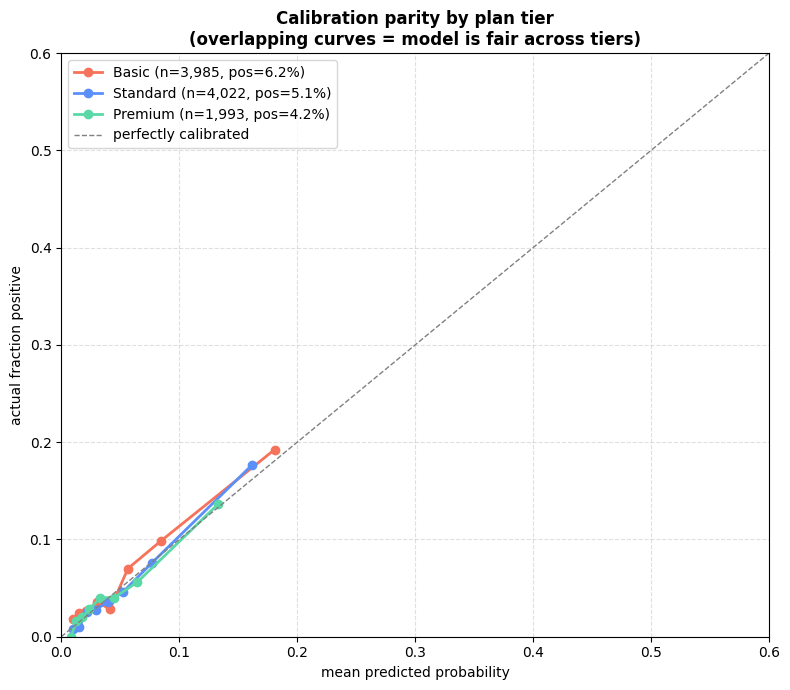

In [4]:
print("\n" + "=" * 70)
print("C. CALIBRATION PARITY BY PLAN TIER")
print("=" * 70)

fig, ax = plt.subplots(figsize=(8, 7))
colors = {"Basic": "#F6735B", "Standard": "#5B8FF9", "Premium": "#5AD8A6"}
for tier, color in colors.items():
    mask = segments["plan_tier"] == tier
    y_sub = y_true[mask]
    p_sub = p_churn[mask]
    if len(y_sub) < 100:
        continue
    cal = calibration_curve_points(y_sub, p_sub, n_bins=8)
    ax.plot(cal["mean_pred"], cal["frac_positive"], marker="o",
            linewidth=2, color=color,
            label=f"{tier} (n={len(y_sub):,}, pos={y_sub.mean():.1%})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--",
        linewidth=1, label="perfectly calibrated")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("actual fraction positive")
ax.set_title("Calibration parity by plan tier\n"
             "(overlapping curves = model is fair across tiers)",
             fontweight="bold")
ax.set_xlim(0, 0.6)
ax.set_ylim(0, 0.6)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(FIG_DIR / "05b_calibration_by_tier.png", dpi=140, bbox_inches="tight")
print(f"Saved -> {FIG_DIR}/05b_calibration_by_tier.png")
plt.show()

## C.2. Calibration parity by engagement cohort

The plan-tier calibration in Section C is standard; this stratifies by
engagement cohort, which is where the real story lives — engagement patterns
drive churn behavior more than plan tier does, so calibration miscalibration
is more likely to show up here.


C.2. CALIBRATION PARITY BY ENGAGEMENT COHORT


Saved -> reports/figures/05b_calibration_by_cohort.png


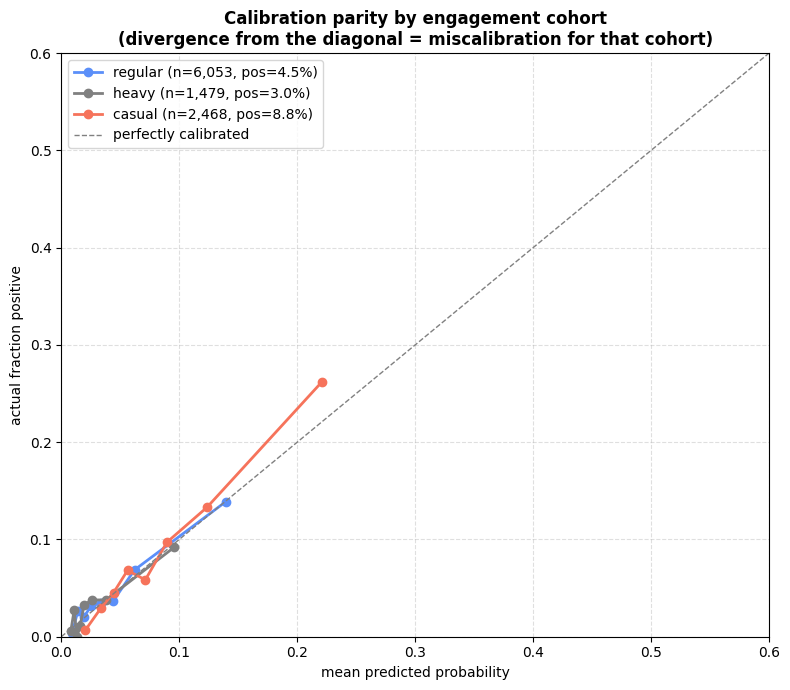

In [5]:
print("\n" + "=" * 70)
print("C.2. CALIBRATION PARITY BY ENGAGEMENT COHORT")
print("=" * 70)

fig, ax = plt.subplots(figsize=(8, 7))
cohort_colors = {
    "casual":  "#F6735B",
    "regular": "#5B8FF9",
    "power":   "#5AD8A6",
}
for cohort in segments["engagement_cohort"].unique():
    mask = segments["engagement_cohort"] == cohort
    y_sub = y_true[mask]
    p_sub = p_churn[mask]
    if len(y_sub) < 100:
        continue
    cal = calibration_curve_points(y_sub, p_sub, n_bins=8)
    color = cohort_colors.get(str(cohort), "gray")
    ax.plot(cal["mean_pred"], cal["frac_positive"], marker="o",
            linewidth=2, color=color,
            label=f"{cohort} (n={len(y_sub):,}, pos={y_sub.mean():.1%})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--",
        linewidth=1, label="perfectly calibrated")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("actual fraction positive")
ax.set_title("Calibration parity by engagement cohort\n"
             "(divergence from the diagonal = miscalibration for that cohort)",
             fontweight="bold")
ax.set_xlim(0, 0.6)
ax.set_ylim(0, 0.6)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(FIG_DIR / "05b_calibration_by_cohort.png",
            dpi=140, bbox_inches="tight")
print(f"Saved -> {FIG_DIR}/05b_calibration_by_cohort.png")
plt.show()

## D. Calibration-in-the-large by segment

Brier score is reported for reference, but it is NOT a calibration-parity metric:
it scales with the segment's base rate (p(1-p)), so a high-churn segment has a higher
Brier even when the model is perfectly calibrated there. The check that matters for
the EV rule is whether predicted churn matches observed churn within each segment:
the ratio of mean predicted P(churn) to the observed rate, with a binomial test of the
observed churner count against the count the model predicts.


D. CALIBRATION-IN-THE-LARGE BY SEGMENT (test rows)
      segment_col    segment    n  observed  predicted  pred_over_obs  binom_p  brier
    tenure_bucket        m12  291    0.0825     0.0494         0.5989   0.0141 0.0731
    tenure_bucket       m3-5 1902    0.0620     0.0540         0.8708   0.1278 0.0545
        plan_tier      Basic 3985    0.0617     0.0550         0.8915   0.0656 0.0541
engagement_cohort      heavy 1479    0.0304     0.0283         0.9315   0.5838 0.0284
engagement_cohort     casual 2468    0.0875     0.0825         0.9424   0.3603 0.0734
engagement_cohort    regular 6053    0.0451     0.0433         0.9606   0.4874 0.0414
    tenure_bucket m0-2 trial 2581    0.0697     0.0678         0.9723   0.6954 0.0595
    tenure_bucket      m6-11 2587    0.0491     0.0488         0.9935   0.9272 0.0451
        plan_tier   Standard 4022    0.0507     0.0508         1.0010   1.0000 0.0451
        plan_tier    Premium 1993    0.0421     0.0422         1.0023   1.0000 0.0384
  


Saved -> reports/figures/05b_calibration_by_segment.png


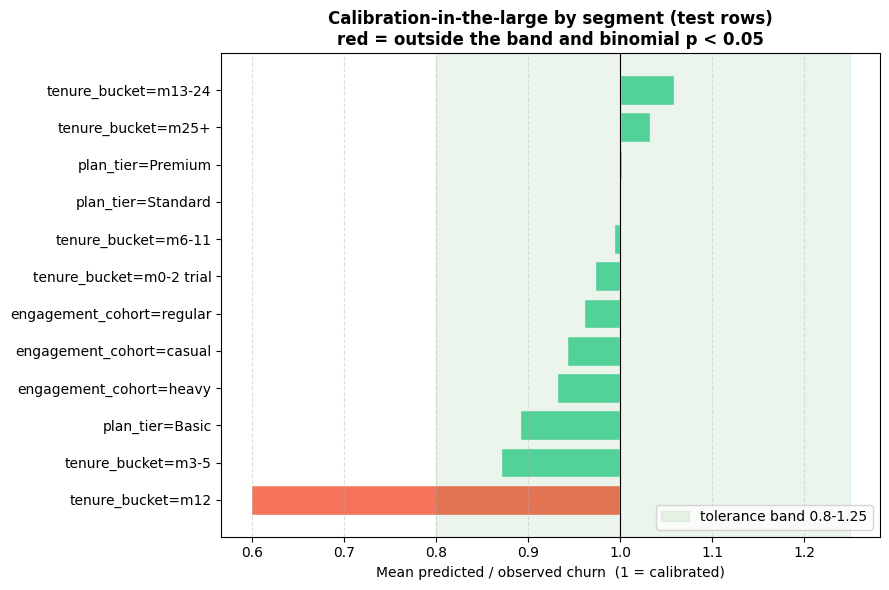

In [6]:
print("\n" + "=" * 70)
print("D. CALIBRATION-IN-THE-LARGE BY SEGMENT (test rows)")
print("=" * 70)

brier_rows = []
for seg_col in ["plan_tier", "engagement_cohort", "tenure_bucket"]:
    for val, sub in segments.groupby(seg_col, observed=True):
        idx = sub.index
        y_sub = y_true[idx]
        p_sub = p_churn[idx]
        if len(y_sub) < 100:
            continue
        b = brier_score_loss(y_sub, p_sub)
        expected = p_sub.mean()
        observed = y_sub.mean()
        test = binomtest(int(y_sub.sum()), len(y_sub), float(expected))
        brier_rows.append({
            "segment_col": seg_col, "segment": str(val),
            "n": len(y_sub), "observed": observed, "predicted": expected,
            "pred_over_obs": expected / observed if observed > 0 else np.nan,
            "binom_p": test.pvalue,
            "brier": b, "delta_vs_overall": b - overall_brier,
        })
brier_df = pd.DataFrame(brier_rows).sort_values("pred_over_obs")
print(brier_df.drop(columns=["delta_vs_overall"]).round(4).to_string(index=False))
print("\npred_over_obs > 1: the model over-predicts churn in that segment; < 1: under-predicts.")

fig, ax = plt.subplots(figsize=(9, 6))
cal_sorted = brier_df.sort_values("pred_over_obs")
flag = ((cal_sorted["pred_over_obs"] < 0.8) | (cal_sorted["pred_over_obs"] > 1.25)) & \
       (cal_sorted["binom_p"] < 0.05)
ax.barh([f"{r['segment_col']}={r['segment']}" for _, r in cal_sorted.iterrows()],
        cal_sorted["pred_over_obs"] - 1, left=1,
        color=np.where(flag, "#F6735B", "#5AD8A6"), edgecolor="white")
ax.axvline(1, color="black", linewidth=0.8)
ax.axvspan(0.8, 1.25, alpha=0.08, color="green", label="tolerance band 0.8-1.25")
ax.set_xlabel("Mean predicted / observed churn  (1 = calibrated)")
ax.set_title("Calibration-in-the-large by segment (test rows)\n"
             "red = outside the band and binomial p < 0.05", fontweight="bold")
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(FIG_DIR / "05b_calibration_by_segment.png", dpi=140, bbox_inches="tight")
print(f"\nSaved -> {FIG_DIR}/05b_calibration_by_segment.png")
plt.show()

## E. Targeting rate parity — does the v1 policy over/under-serve any group?

Run v1 policy (propensity, full menu, the brief budget scaled to the sample) on the
whole base and check what fraction of each
segment gets targeted. A big spread means the policy is concentrated on certain
segments -- may be legitimate (highest-EV users are in that segment) or may be a
fairness concern (segment gets systematically ignored).

In [7]:
print("\n" + "=" * 70)
print("E. TARGETING RATE BY SEGMENT (v1 policy)")
print("=" * 70)

ltv = raw["plan_tier"].map(LTV_BY_TIER).values
policy = build_policy(p_all, ltv, budget=BUDGET)
targeted = policy["will_target"].values

overall_target_rate = targeted.mean()
print(f"\nOverall targeting rate: {overall_target_rate:.2%}")
print(f"(This is the fraction of the {len(policy):,}-user base the policy "
      f"targets under the monthly budget (${BUDGET:,.0f} for this sample). Segment "
      f"target rates below are stated relative to this baseline.)\n")

# Collect per-segment target rates so Section G can auto-flag any that
# are systematically under-served (rate_ratio_vs_overall < 0.5).
target_rate_rows = []
for seg_col in ["plan_tier", "engagement_cohort", "tenure_bucket", "country"]:
    print(f"By {seg_col}:")
    seg_rows = []
    for val, sub in segments_all.groupby(seg_col, observed=True):
        idx = sub.index
        n = len(sub)
        n_targeted = int(targeted[idx].sum())
        rate = n_targeted / n if n else 0
        row = {
            "segment_col": seg_col, "segment": str(val),
            "n": n, "n_targeted": n_targeted,
            "target_rate": rate,
            "rate_ratio_vs_overall": rate / overall_target_rate
            if overall_target_rate > 0 else 0,
        }
        seg_rows.append(row)
        target_rate_rows.append(row)
    print(pd.DataFrame(seg_rows).drop(columns=["segment_col"])
          .round(3).to_string(index=False))
    print()
target_rate_df = pd.DataFrame(target_rate_rows)


E. TARGETING RATE BY SEGMENT (v1 policy)

Overall targeting rate: 5.67%
(This is the fraction of the 50,000-user base the policy targets under the monthly budget ($4,762 for this sample). Segment target rates below are stated relative to this baseline.)

By plan_tier:
 segment     n  n_targeted  target_rate  rate_ratio_vs_overall
   Basic 19864         463        0.023                  0.411
 Premium  9942        1015        0.102                  1.802
Standard 20194        1355        0.067                  1.184

By engagement_cohort:
segment     n  n_targeted  target_rate  rate_ratio_vs_overall
 casual 12425        1608        0.129                  2.284
  heavy  7479         121        0.016                  0.286
regular 30096        1104        0.037                  0.647

By tenure_bucket:
   segment     n  n_targeted  target_rate  rate_ratio_vs_overall
m0-2 trial 13118        1287        0.098                  1.732
      m3-5  9606         571        0.059                 

## F. Recall parity (equal opportunity) among true churners

Of the users who actually churned, what fraction did the policy target?
If the recall is 40% for one segment and 15% for another, we're systematically
leaving churners on the table for the under-served group. This is the classic
"equal opportunity" fairness metric.

In [8]:
print("\n" + "=" * 70)
print("F. RECALL PARITY ON TRUE CHURNERS (v1 policy)")
print("=" * 70)

churner_mask = y_all == 1
overall_recall = targeted[churner_mask].mean() if churner_mask.sum() else 0
print(f"\nOverall recall on true churners: {overall_recall:.2%}\n")

# Collect per-segment recall so Section G can auto-flag any segment with
# recall_ratio_vs_overall < 0.5 (classic equal-opportunity failure).
recall_rows = []
for seg_col in ["plan_tier", "engagement_cohort", "tenure_bucket"]:
    print(f"By {seg_col}:")
    rows = []
    for val, sub in segments_all.groupby(seg_col, observed=True):
        idx = sub.index
        y_sub = y_all[idx]
        churners = idx[y_sub == 1]
        n_churners = len(churners)
        if n_churners == 0:
            continue
        recall = targeted[churners].mean()
        row = {
            "segment_col": seg_col, "segment": str(val),
            "n_churners": n_churners,
            "recall": recall,
            "recall_ratio_vs_overall": recall / overall_recall
            if overall_recall else 0,
        }
        rows.append(row)
        recall_rows.append(row)
    print(pd.DataFrame(rows).drop(columns=["segment_col"])
          .round(3).to_string(index=False))
    print()
recall_df = pd.DataFrame(recall_rows)


F. RECALL PARITY ON TRUE CHURNERS (v1 policy)

Overall recall on true churners: 23.69%

By plan_tier:
 segment  n_churners  recall  recall_ratio_vs_overall
   Basic        1229   0.138                    0.584
 Premium         385   0.377                    1.590
Standard        1058   0.301                    1.269

By engagement_cohort:
segment  n_churners  recall  recall_ratio_vs_overall
 casual        1096   0.338                    1.425
  heavy         220   0.155                    0.652
regular        1356   0.169                    0.713

By tenure_bucket:


   segment  n_churners  recall  recall_ratio_vs_overall
m0-2 trial         963   0.313                    1.319
      m3-5         560   0.241                    1.018
     m6-11         610   0.193                    0.817
       m12         102   0.176                    0.745
    m13-24         332   0.172                    0.725
      m25+         105   0.038                    0.161



## G. Verdict — segment audit summary

In [9]:
print("\n" + "=" * 70)
print("G. FAIRNESS AUDIT VERDICT")
print("=" * 70)

# ------------------------------------------------------------------
# Thresholds for auto-flagging concerns.
#
# CALIBRATION: flag a segment when predicted/observed churn is outside
#   [0.8, 1.25] AND the binomial test rejects at p < 0.05 (so small,
#   noisy segments are not flagged on chance alone).
#
# RATE_RATIO_THRESHOLD = 0.5
#   Standard "80% rule"-adjacent heuristic (we use 0.5 = 2x asymmetry
#   as the harder line). Segments getting < half the overall targeting
#   or recall rate are systematically under-served.
# ------------------------------------------------------------------
CAL_BAND = (0.8, 1.25)
RATE_RATIO_THRESHOLD = 0.5

concerns = []

# --- (a) Calibration concerns --------------------------------------
for _, row in brier_df.iterrows():
    r = row["pred_over_obs"]
    if (r < CAL_BAND[0] or r > CAL_BAND[1]) and row["binom_p"] < 0.05:
        concerns.append({
            "kind": "CALIBRATION",
            "segment": f"{row['segment_col']}={row['segment']}",
            "detail": (f"predicted {row['predicted']:.2%} vs observed "
                       f"{row['observed']:.2%} churn (ratio {r:.2f}, "
                       f"binomial p = {row['binom_p']:.3f}, n = {row['n']:,})"),
            "action": ("Add a segment-aware calibrator or include the segment "
                       "in the calibration model."),
        })

# --- (b) Under-service in targeting rate --------------------------
for _, row in target_rate_df.iterrows():
    if row["rate_ratio_vs_overall"] < RATE_RATIO_THRESHOLD:
        concerns.append({
            "kind": "UNDER-SERVED",
            "segment": f"{row['segment_col']}={row['segment']}",
            "detail": (f"target rate {row['target_rate']:.2%} = "
                       f"{row['rate_ratio_vs_overall']:.2f}x overall "
                       f"({overall_target_rate:.2%})"),
            "action": ("Check for feature drift or LTV under-estimation for "
                       "this segment; may need cohort-specific EV thresholds."),
        })

# --- (c) Equal-opportunity failure in recall ----------------------
for _, row in recall_df.iterrows():
    if row["recall_ratio_vs_overall"] < RATE_RATIO_THRESHOLD:
        concerns.append({
            "kind": "RECALL",
            "segment": f"{row['segment_col']}={row['segment']}",
            "detail": (f"recall on true churners {row['recall']:.2%} = "
                       f"{row['recall_ratio_vs_overall']:.2f}x overall "
                       f"({overall_recall:.2%})"),
            "action": ("Recommend cohort-weighted retraining, or a "
                       "segment-specific score adjustment to raise recall "
                       "on this group."),
        })

print(f"""
Summary:
  Overall PR-AUC:                {overall_pr:.4f}
  Overall Brier:                 {overall_brier:.4f}
  Overall v1 targeting rate:     {overall_target_rate:.2%}
  Overall v1 recall on churners: {overall_recall:.2%}

Thresholds used to auto-flag concerns:
  Predicted/observed churn outside {CAL_BAND[0]}-{CAL_BAND[1]} with binomial p < 0.05
  Target-rate ratio  < {RATE_RATIO_THRESHOLD} (segment under-served)
  Recall ratio       < {RATE_RATIO_THRESHOLD} (equal-opportunity failure)

Segment-level concerns detected: {len(concerns)}
""")

for c in concerns:
    print(f"  [{c['kind']:<12}] {c['segment']}")
    print(f"                  {c['detail']}")
    print(f"                  -> {c['action']}\n")

if not concerns:
    print(f"""  None. All segments perform within noise on all three checks:
    calibration within band, target rate >= {RATE_RATIO_THRESHOLD}x overall,
    recall >= {RATE_RATIO_THRESHOLD}x overall. Targeting-rate variation across segments
    reflects legitimate churn-rate + LTV differences captured by the
    model, not systematic under-service.
""")

print("""
Reading this audit for the memo:
  - Calibration is the key thing to watch. If P(churn) means different
    things for different tiers / cohorts, the EV budget is being spent
    unequally even when the aggregate numbers look fine.
  - Low targeting of a low-churn segment (heavy users, long tenure) is
    the EV rule working, not a defect: the question is whether those
    users' churn is UNDER-predicted, which Section D checks.
  - Targeting-rate spread across segments is EXPECTED (higher-churn or
    higher-LTV segments legitimately get more intervention). What's
    NOT expected is a segment being systematically dropped -- caught
    by the UNDER-SERVED check above.
  - Recall parity is the equal-opportunity metric: does the policy
    catch churners at the same rate across segments? A big spread
    signals systematic under-service -- caught by the RECALL check.

Charts for the memo:
  - reports/figures/05b_calibration_by_tier.png
  - reports/figures/05b_calibration_by_cohort.png
  - reports/figures/05b_calibration_by_segment.png
""")


G. FAIRNESS AUDIT VERDICT

Summary:
  Overall PR-AUC:                0.1773
  Overall Brier:                 0.0474
  Overall v1 targeting rate:     5.67%
  Overall v1 recall on churners: 23.69%

Thresholds used to auto-flag concerns:
  Predicted/observed churn outside 0.8-1.25 with binomial p < 0.05
  Target-rate ratio  < 0.5 (segment under-served)
  Recall ratio       < 0.5 (equal-opportunity failure)

Segment-level concerns detected: 6

  [CALIBRATION ] tenure_bucket=m12
                  predicted 4.94% vs observed 8.25% churn (ratio 0.60, binomial p = 0.014, n = 291)
                  -> Add a segment-aware calibrator or include the segment in the calibration model.

  [UNDER-SERVED] plan_tier=Basic
                  target rate 2.33% = 0.41x overall (5.67%)
                  -> Check for feature drift or LTV under-estimation for this segment; may need cohort-specific EV thresholds.

  [UNDER-SERVED] engagement_cohort=heavy
                  target rate 1.62% = 0.29x overall (5.6